# release_june_26 — inference log vs emulator (MP4 / lossless) vs device log vs post-zeroing log

Side-by-side of the same 3 test frames under six inference pipelines:

| Row | Source | What it is |
| --- | ------ | ---------- |
| **Arm ML kit (pre-zero)** | `inference_log_gt.txt` | Arm ML Embedded Eval Kit reference run *before* the input-tensor tail was zeroed. The unused 76800 bytes of the `[1,320,320,3]` input tensor held arena garbage. |
| **Emu (MP4 · wb_alif)** | `output-2026-07-07-19-29-55_int8_regr_b1_10_wb/` | Emulator @ int8 backbone + `wb_alif` ridge-regression correction, `conf_th=0.2`, `iou_th=0.45`, source = lossy `mp4v` MP4. |
| **Emu (lossless · wb_alif)** | `output-2026-07-08-20-04-34_int8_regr_b1_10_wb_lossless/` | Same emulator config as above but source is the lossless `FFV1/MKV` re-encode. Isolates codec-loss impact. |
| **Emu (lossless · rq_bg_clahe)** | `output-2026-07-08-20-04-37_int8_regr_b1_10_rq_bg_clahe_lossless/` | Emulator @ int8 backbone + `rq_bg_wb_alif_clahe` ridge-regression correction, lossless source. This is the correction JSON the native pipeline is actually compiled with (`ENABLE_CLAHE_MODEL=ON`). |
| **Device** | `images/logs.txt` | pg2gw deployed-device syslog. Multi-frame stream; detections deduped by `(x,y,w,h)` and confidence kept as the max across frames. |
| **Arm ML kit (post-zero)** | `inference_log_zeroed.txt` | Same native pipeline *after* the fix at `DetectorPreProcessing.cc:DoPreProcess` that `memset`s the trailing `tensorBytes - inputSize` bytes to zero. |

**Arm ML kit log format:**
```
INFO - Running inference on image 0 => 6100001-2000-000008-2550.bmp
Final results:
Total number of inferences: 1
Box: [186.29 210.55 80.50 41.94]. Position: [206.78 222.62]. Confidence: 0.66
```
Both Arm ML logs cover 6 images; the first 3 are our sensor frames, the last 3 (`img_32`, `img_320`, `img_320_no_clahe`) are unrelated validation samples and are skipped.

**Device log format:**
```
Jul 02 06:35:55 DUSUN pg2gw[687]: Detection translated for sensor 6100002-2000-000008-2550: pixel(185,204) -> cm(47,-151). conf = 0.730469; box: x = 156, y = 184, w = 82, h = 60
```

All six coord systems are absolute pixels in the 320×240 frame; `box = [x, y, w, h]` top-left, `position/pixel = [x, y]` leg keypoint. Emulator preds are denormalized as in `visualize_model_comparison.ipynb`.

In [21]:
import json
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path('.')
IMAGES_DIR = ROOT / 'images'
ARM_LOG_PATH = ROOT / 'inference_log_gt.txt'
ARM_LOG_ZEROED_PATH = ROOT / 'inference_log_zeroed.txt'
DEVICE_LOG_PATH = IMAGES_DIR / 'logs.txt'

EMU_DIR_MP4_WB           = ROOT / 'output-2026-07-07-19-29-55_int8_regr_b1_10_wb'
EMU_DIR_LOSSLESS_WB      = ROOT / 'output-2026-07-08-20-04-34_int8_regr_b1_10_wb_lossless'
EMU_DIR_LOSSLESS_RQ_BG   = ROOT / 'output-2026-07-08-20-04-37_int8_regr_b1_10_rq_bg_clahe_lossless'

SENSORS = [
    ('6100002-2000-000008-2550', 'AlgoA — KlymLatest'),
    ('6200001-2000-000008-2550', 'AlgoB — MasterTest'),
    ('6100001-2000-000008-2550', 'AlgoC — KlymLatest_canDriver'),
]

IMG_W, IMG_H = 320, 240

In [22]:
ARM_IMG_RE = re.compile(r'Running inference on image \d+ => (?P<name>\S+)\.bmp')
ARM_DET_RE = re.compile(
    r'Box:\s*\[\s*(?P<x>-?[\d.]+)\s+(?P<y>-?[\d.]+)\s+(?P<w>-?[\d.]+)\s+(?P<h>-?[\d.]+)\s*\]\.\s*'
    r'Position:\s*\[\s*(?P<px>-?[\d.]+)\s+(?P<py>-?[\d.]+)\s*\]\.\s*'
    r'Confidence:\s*(?P<conf>[\d.]+)'
)

def parse_arm_log(log_path):
    """{stem: [{x,y,w,h,px,py,conf}, ...]} keyed by .bmp basename (no ext)."""
    frames = {}
    cur = None
    for line in log_path.read_text().splitlines():
        im = ARM_IMG_RE.search(line)
        if im:
            cur = im.group('name')
            frames[cur] = []
            continue
        d = ARM_DET_RE.search(line)
        if d and cur is not None:
            frames[cur].append(dict(
                x=float(d['x']), y=float(d['y']),
                w=float(d['w']), h=float(d['h']),
                px=float(d['px']), py=float(d['py']),
                conf=float(d['conf']),
            ))
    return frames

arm_frames = parse_arm_log(ARM_LOG_PATH)
arm_zeroed_frames = parse_arm_log(ARM_LOG_ZEROED_PATH)
{'pre_zero': {k: len(v) for k, v in arm_frames.items()},
 'post_zero': {k: len(v) for k, v in arm_zeroed_frames.items()}}

{'pre_zero': {'6100001-2000-000008-2550': 1,
  '6100002-2000-000008-2550': 1,
  '6200001-2000-000008-2550': 0,
  'img_32': 4,
  'img_320': 3,
  'img_320_no_clahe': 2},
 'post_zero': {'6100001-2000-000008-2550': 1,
  '6100002-2000-000008-2550': 1,
  '6200001-2000-000008-2550': 0,
  'img_32': 5,
  'img_320': 2,
  'img_320_no_clahe': 2}}

In [23]:
DEV_DET_RE = re.compile(
    r'Detection translated for sensor (?P<sensor>[\w-]+):\s*'
    r'pixel\((?P<px>-?\d+),(?P<py>-?\d+)\)\s*->\s*'
    r'cm\((?P<cx>-?\d+),(?P<cy>-?\d+)\)\.\s*'
    r'conf\s*=\s*(?P<conf>[\d.]+);\s*'
    r'box:\s*x\s*=\s*(?P<x>-?\d+),\s*y\s*=\s*(?P<y>-?\d+),\s*'
    r'w\s*=\s*(?P<w>\d+),\s*h\s*=\s*(?P<h>\d+)'
)

def parse_device_log(log_path):
    """{sensor: [{x,y,w,h,px,py,conf}, ...]} deduped by (x,y,w,h); conf = max across frames."""
    buckets = defaultdict(dict)
    for line in log_path.read_text().splitlines():
        m = DEV_DET_RE.search(line)
        if not m:
            continue
        s = m.group('sensor')
        box = (int(m['x']), int(m['y']), int(m['w']), int(m['h']))
        conf = float(m['conf'])
        prev = buckets[s].get(box)
        if prev is None:
            buckets[s][box] = dict(
                x=box[0], y=box[1], w=box[2], h=box[3],
                px=int(m['px']), py=int(m['py']),
                conf=conf,
            )
        elif conf > prev['conf']:
            prev['conf'] = conf
    return {s: list(d.values()) for s, d in buckets.items()}

device_frames = parse_device_log(DEVICE_LOG_PATH)
{s[:7]: len(v) for s, v in device_frames.items()}

{'6100002': 3, '6200001': 2}

In [24]:
def load_emu_preds(emu_dir, sensor, ts=0):
    data = json.loads((emu_dir / f'{sensor}_predictions.json').read_text())
    for frame in data:
        if frame['ts'] == ts:
            return frame['preds']
    return []

def emu_to_pixels(preds):
    """Denormalize emu preds into the same absolute-pixel shape as the log parsers."""
    out = []
    for p in preds:
        bx, by, bw, bh = p['bbox']
        px, py = p['position']
        out.append(dict(
            x=bx * IMG_W, y=by * IMG_H, w=bw * IMG_W, h=bh * IMG_H,
            px=px * IMG_W, py=py * IMG_H,
            conf=p['confidence'],
        ))
    return out

# sanity: detection counts per source per sensor
hdr = f'{"sensor":8s} | {"arm":>3s} | {"mp4wb":>5s} | {"lswb":>4s} | {"lsrq":>4s} | {"dev":>3s} | {"arm0":>4s}'
print(hdr)
print('-' * len(hdr))
for sensor, _ in SENSORS:
    n_arm    = len(arm_frames.get(sensor, []))
    n_mp4wb  = len(load_emu_preds(EMU_DIR_MP4_WB,         sensor))
    n_lswb   = len(load_emu_preds(EMU_DIR_LOSSLESS_WB,    sensor))
    n_lsrq   = len(load_emu_preds(EMU_DIR_LOSSLESS_RQ_BG, sensor))
    n_dev    = len(device_frames.get(sensor, []))
    n_arm0   = len(arm_zeroed_frames.get(sensor, []))
    print(f'{sensor[:7]:8s} | {n_arm:>3d} | {n_mp4wb:>5d} | {n_lswb:>4d} | {n_lsrq:>4d} | {n_dev:>3d} | {n_arm0:>4d}')

sensor   | arm | mp4wb | lswb | lsrq | dev | arm0
-------------------------------------------------
6100002  |   1 |     2 |    1 |    1 |   3 |    1
6200001  |   0 |     2 |    0 |    0 |   2 |    0
6100001  |   1 |     2 |    1 |    1 |   0 |    1


In [25]:
def conf_color(conf):
    if conf < 0.5:
        return '#ff3030'
    if conf < 0.7:
        return '#ff9f1c'
    return '#2ecc40'

def draw_dets(ax, img_path, dets, title):
    ax.imshow(Image.open(img_path).convert('RGB'))
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    for d in dets:
        c = conf_color(d['conf'])
        ax.add_patch(Rectangle(
            (d['x'], d['y']), d['w'], d['h'],
            linewidth=1.6, edgecolor=c, facecolor='none',
        ))
        ax.plot(d['px'], d['py'], marker='+', color=c, markersize=9, mew=1.6)
        ax.text(
            d['x'] + 2, max(d['y'] - 3, 8), f"{d['conf']:.2f}",
            fontsize=7, color='white',
            bbox=dict(facecolor=c, edgecolor='none', pad=1, alpha=0.85),
        )

## Grid — 6 sources (rows) × 3 sensors (cols)

Box = bbox in pixel coords, `+` = leg keypoint. Label = confidence. Colors: red `<0.5`, orange `<0.7`, green `≥0.7`.

- Row 2 → Row 3 isolates **codec-loss impact** (MP4 vs lossless FFV1, same `wb_alif` correction).
- Row 3 → Row 4 isolates **correction-JSON impact** (`wb_alif` vs `rq_bg_wb_alif_clahe` — matches what native is compiled with, both on lossless source).
- Row 1 → Row 6 isolates the **input-tensor-tail zeroing** on native.

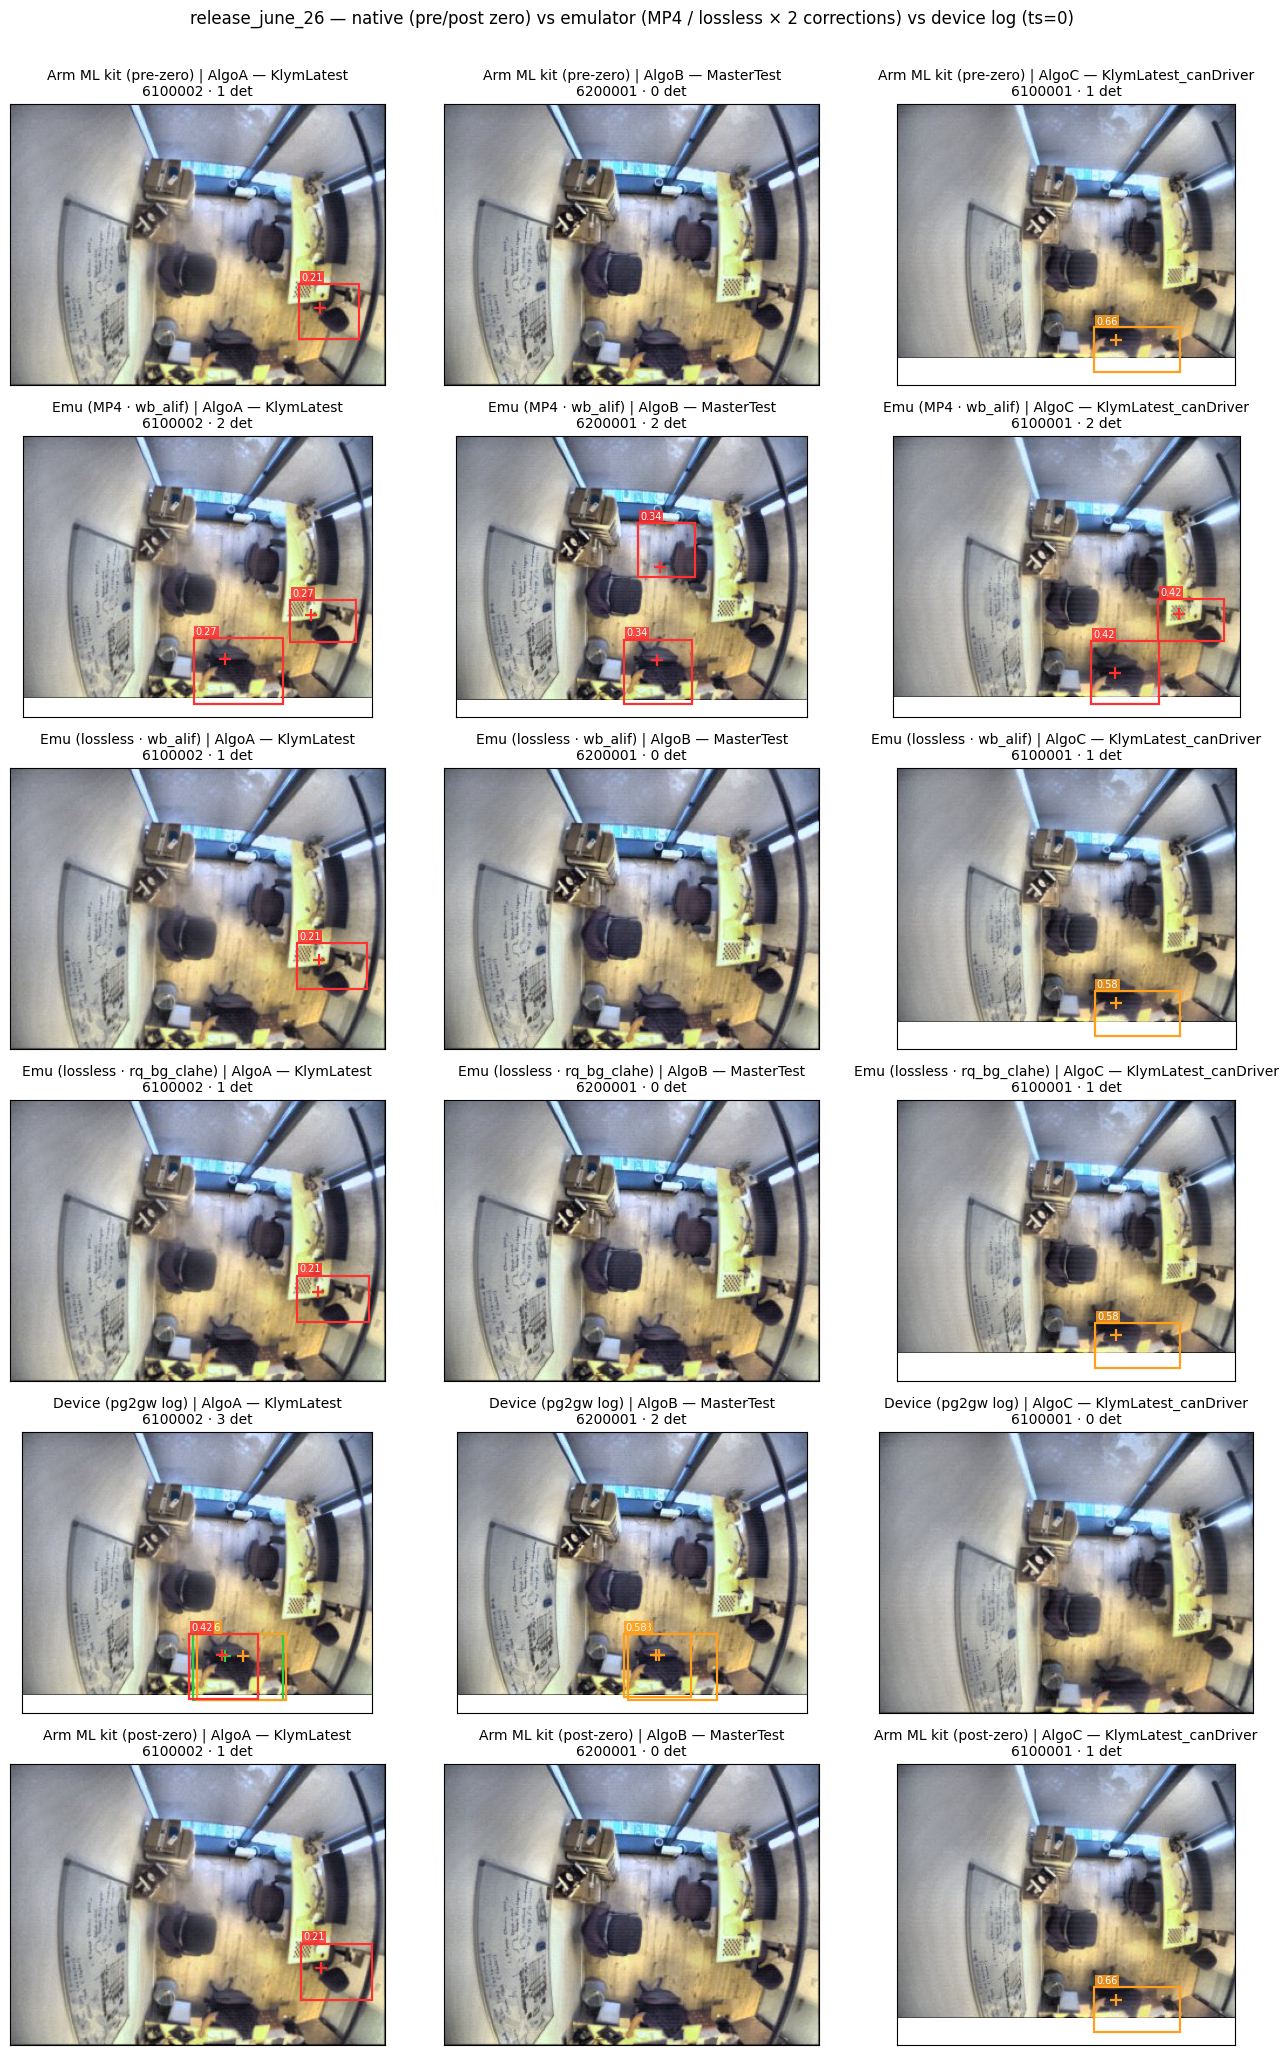

In [26]:
SOURCES = [
    ('Arm ML kit (pre-zero)',        lambda sensor: arm_frames.get(sensor, [])),
    ('Emu (MP4 · wb_alif)',          lambda sensor: emu_to_pixels(load_emu_preds(EMU_DIR_MP4_WB,         sensor))),
    ('Emu (lossless · wb_alif)',     lambda sensor: emu_to_pixels(load_emu_preds(EMU_DIR_LOSSLESS_WB,    sensor))),
    ('Emu (lossless · rq_bg_clahe)', lambda sensor: emu_to_pixels(load_emu_preds(EMU_DIR_LOSSLESS_RQ_BG, sensor))),
    ('Device (pg2gw log)',           lambda sensor: device_frames.get(sensor, [])),
    ('Arm ML kit (post-zero)',       lambda sensor: arm_zeroed_frames.get(sensor, [])),
]

rows, cols = len(SOURCES), len(SENSORS)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.4, rows * 3.4), squeeze=False)

for r, (src_label, loader) in enumerate(SOURCES):
    for c, (sensor, algo_label) in enumerate(SENSORS):
        dets = loader(sensor)
        title = f'{src_label} | {algo_label}\n{sensor[:7]} · {len(dets)} det'
        draw_dets(axes[r][c], IMAGES_DIR / f'{sensor}.jpg', dets, title)

fig.suptitle('release_june_26 — native (pre/post zero) vs emulator (MP4 / lossless × 2 corrections) vs device log (ts=0)', fontsize=12, y=1.005)
fig.tight_layout()
plt.show()

## Numeric side-by-side

Rows are printed in the order each source emitted them — no attempt to match detections across sources (counts and orders can differ, as sanity check above shows). Read each block as "same sensor, different pipeline".

In [27]:
def fmt(d):
    return (f"box=({d['x']:6.2f},{d['y']:6.2f},{d['w']:6.2f},{d['h']:6.2f})  "
            f"pos=({d['px']:6.2f},{d['py']:6.2f})  conf={d['conf']:.3f}")

for sensor, algo_label in SENSORS:
    print(f'=== {sensor[:7]} — {algo_label} ===')
    arm_d    = arm_frames.get(sensor, [])
    mp4wb_d  = emu_to_pixels(load_emu_preds(EMU_DIR_MP4_WB,         sensor))
    lswb_d   = emu_to_pixels(load_emu_preds(EMU_DIR_LOSSLESS_WB,    sensor))
    lsrq_d   = emu_to_pixels(load_emu_preds(EMU_DIR_LOSSLESS_RQ_BG, sensor))
    dev_d    = device_frames.get(sensor, [])
    arm0_d   = arm_zeroed_frames.get(sensor, [])
    print(f'  Arm ML kit (pre-zero) ({len(arm_d)}):')
    for d in arm_d: print('   ', fmt(d))
    print(f'  Emu (MP4 · wb_alif) ({len(mp4wb_d)}):')
    for d in mp4wb_d: print('   ', fmt(d))
    print(f'  Emu (lossless · wb_alif) ({len(lswb_d)}):')
    for d in lswb_d: print('   ', fmt(d))
    print(f'  Emu (lossless · rq_bg_clahe) ({len(lsrq_d)}):')
    for d in lsrq_d: print('   ', fmt(d))
    print(f'  Device ({len(dev_d)}):')
    for d in dev_d: print('   ', fmt(d))
    print(f'  Arm ML kit (post-zero) ({len(arm0_d)}):')
    for d in arm0_d: print('   ', fmt(d))
    print()

=== 6100002 — AlgoA — KlymLatest ===
  Arm ML kit (pre-zero) (1):
    box=(246.02,152.93, 51.44, 46.99)  pos=(264.17,173.54)  conf=0.210
  Emu (MP4 · wb_alif) (2):
    box=(244.48,149.13, 60.40, 38.94)  pos=(263.25,163.26)  conf=0.270
    box=(156.19,184.54, 81.90, 60.04)  pos=(184.84,203.55)  conf=0.270
  Emu (lossless · wb_alif) (1):
    box=(244.48,149.13, 60.40, 38.94)  pos=(263.25,163.26)  conf=0.211
  Emu (lossless · rq_bg_clahe) (1):
    box=(244.85,149.55, 61.05, 39.29)  pos=(262.88,163.73)  conf=0.211
  Device (3):
    box=(156.00,184.00, 82.00, 60.00)  pos=(185.00,204.00)  conf=0.730
    box=(159.00,184.00, 82.00, 60.00)  pos=(201.00,204.00)  conf=0.660
    box=(152.00,184.00, 63.00, 59.00)  pos=(182.00,203.00)  conf=0.418
  Arm ML kit (post-zero) (1):
    box=(247.87,152.89, 61.27, 47.76)  pos=(265.39,173.78)  conf=0.210

=== 6200001 — AlgoB — MasterTest ===
  Arm ML kit (pre-zero) (0):
  Emu (MP4 · wb_alif) (2):
    box=(165.41, 78.39, 51.79, 49.18)  pos=(185.09,118.78)  co